In [217]:
"""
<앙상블 모델>
 - 결정트리를 기반으로 만들어진 모델
 - 여러개의 트리 모델을 이용하여 훈련하는 모델을 앙상블 모델이라고 칭합니다.
 - 여러개의 트리 모델들이 모여있다고 해서 앙상블 이라고 칭합니다.
 - 교차검증 수행방식을 포함하고 있는 모델임


<앙상블 모델 분류>
 * 회귀와 분류에서 모두 사용가능한 모델
  - sklearn 패키지 모델은 모두 가능
  - 랜덤포레스트, 엑스트라트리, 그레디언트 부스팅, 히스토그램 그레디언트 부스팅
  - XGBooting, LightBGM, 등등
"""

"""
-----------------------------------------------------------------------------
<배깅(Bagging)과 부스팅(Boosting) 방식>
 - 훈련데이터를 여러 모델에 적용하는 방식에 따라 배깅과 부스팅 방식으로 구분함


<배깅>
 - 사용되는 여러개의 모델은 서로간에 독립적으로 사용됨(연관성 없음)
 - 훈련데이터는 여러 모델에 랜덤하게 적용되며, 중복되는 데이터가 있을 수도 있음
 - 훈련데이터를 사용 후 반환하는 방식 > 반환 후 다시 랜덤하게 추출하여 사용됨
 - 대표적인 앙상블 모델은 랜덤포레스트 모델이 있음
 - 모델 : 램덤포레스트, 엑스트라트리
 - 예측 : 회귀에서는 평균값을, 분류에서는 과반수에 따라 확률로 결정됨
 ** 과적합을 해소하는 모델로 주로 사용됨
 
<부스팅>
 - 사용되는 여러개의 모델은 연관성을 가짐
 - 사용된 이전모델의 오차를 보완하는 방식으로 사용됨
 - 데이터는 랜덤하게 추출되어 사용되지만,
   이전 모델훈련에서 오차가 크게 발생했던 훈련데이터에 가중치를 부여하는 방식으로
   데이터가 모델에 적용됨
 - 대표적인 앙상블 모델은 그레디언트 부스팅 모델이 있음
 - 모델 : 그레디언트 부스팅, 히스토그램 그레디언트 부스팅
 ** 정확도를 높이는 모델로 주로 사용됨
 
<실제 모델 적용시>
 - 앙상블 모델이 아닌 단일모델(결정트리)을 우선 사용
 - 과적합 또는 정확도 문제 발생 시 배깅 또는 부스팅 방식으로 확대 적용
 - 앙상블 모델은 랜덤포레스트를 처음 적용하는 것이 일반적임
 - 최종 모델 선정 시에는 모든 앙상블 모델을 훈련시킨 후 과적합/정확도/재현율/F1-Score 등을 고려하여
   선정하게 됨
"""

'\n-----------------------------------------------------------------------------\n<배깅(Bagging)과 부스팅(Boosting) 방식>\n - 훈련데이터를 여러 모델에 적용하는 방식에 따라 배깅과 부스팅 방식으로 구분함\n\n\n<배깅>\n - 사용되는 여러개의 모델은 서로간에 독립적으로 사용됨(연관성 없음)\n - 훈련데이터는 여러 모델에 랜덤하게 적용되며, 중복되는 데이터가 있을 수도 있음\n - 훈련데이터를 사용 후 반환하는 방식 > 반환 후 다시 랜덤하게 추출하여 사용됨\n - 대표적인 앙상블 모델은 랜덤포레스트 모델이 있음\n - 모델 : 램덤포레스트, 엑스트라트리\n - 예측 : 회귀에서는 평균값을, 분류에서는 과반수에 따라 확률로 결정됨\n ** 과적합을 해소하는 모델로 주로 사용됨\n \n<부스팅>\n - 사용되는 여러개의 모델은 연관성을 가짐\n - 사용된 이전모델의 오차를 보완하는 방식으로 사용됨\n - 데이터는 랜덤하게 추출되어 사용되지만,\n   이전 모델훈련에서 오차가 크게 발생했던 훈련데이터에 가중치를 부여하는 방식으로\n   데이터가 모델에 적용됨\n - 대표적인 앙상블 모델은 그레디언트 부스팅 모델이 있음\n - 모델 : 그레디언트 부스팅, 히스토그램 그레디언트 부스팅\n ** 정확도를 높이는 모델로 주로 사용됨\n \n<실제 모델 적용시>\n - 앙상블 모델이 아닌 단일모델(결정트리)을 우선 사용\n - 과적합 또는 정확도 문제 발생 시 배깅 또는 부스팅 방식으로 확대 적용\n - 앙상블 모델은 랜덤포레스트를 처음 적용하는 것이 일반적임\n - 최종 모델 선정 시에는 모든 앙상블 모델을 훈련시킨 후 과적합/정확도/재현율/F1-Score 등을 고려하여\n   선정하게 됨\n'

### 라이브러리 불러들이기

In [218]:
### 사용할 라이브러리 불러들이기

# 데이터 조작을 위한 라이브러리
import pandas as pd

# 기본 시각화 라이브러리
import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러리라고 생각하면 됨)
import seaborn as sns

# 시각화 시 그래프의 너비/높이 기본 설정하기(단위=인치)
plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정(Window OS 기준, Mac OS나 Linux는 그에 맞게)
plt.rcParams['font.family'] = 'Malgun Gothic'

# 시각화시 마이너스(-) 기호 깨짐 방지 처리
plt.rcParams['axes.unicode_minus'] = False

### 상관관계 검정()
from scipy.stats import spearmanr, pearsonr

### 훈련/검증/테스트 데이터로 분리하는 함수
from sklearn.model_selection import train_test_split

### 데이터 스케일링 표준화 클래스
from sklearn.preprocessing import StandardScaler

### 사용할 훈련모델 클래스
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier

### 분류분석 오차 확인(평가) 라이브러리
# - 오차행렬표, 오차행렬도(그래프)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

### 분류모델 평가지표(선정기준)
# - 정확도, 정밀도, 재현율, f1-score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

### 데이터 불러들이기

In [219]:
### 사용할 데이터셋 : data 폴더 안에 csv 파일 사용
# - 변수명 : wine
# - 데이터셋 정보확인

file_path = "./dataset/08_wine.csv"
wine = pd.read_csv(file_path)
wine.info()
wine.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   float64
dtypes: float64(4)
memory usage: 203.2 KB


,alcohol,sugar,pH,class
count,6497.000000,6497.000000,6497.000000,6497.000000
mean,10.491801,5.443235,3.218501,0.753886
std,1.192712,4.757804,0.160787,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,14.900000,65.800000,4.010000,1.000000


### 독립변수와 종속변수로 분리하기

In [220]:
### 독립변수명 : data, 종속변수명 : target
# - 독립변수와 종속변수 데이터 타입은 리스트 타입으로(numpy의 array) 변환해서 저장하기

# 독립변수
data = wine.iloc[:,:-1].to_numpy()
data
# 종속변수
target = wine["class"].to_numpy()
target
print(data.shape, target.shape)

(6497, 3) (6497,)


### 훈련:테스트 = 8:2로 분리

In [221]:
### 변수명 : train_input, train_target, test_input, test_target
train_input, test_input, train_target, test_target = train_test_split(data, target, test_size=0.2, stratify=target, random_state=42)

print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)

(5197, 3) (5197,)
(1300, 3) (1300,)


### 데이터 스케일링(표준화) 시키기

In [222]:
"""
<데이터 스케일링>
 - 서로다른 변수의 값의 단위를 일정한 수준으로 맞추는 작업을 스케일링 이라고 칭함
 - 데이터 스케일링을 현업에서는 정규화 또는 표준화라고 소통하고 있음
 - 스케일링 방법 3가지
   -> StandardScaler(표준화), RobustScaler, MinMaxScaler


<주 사용처>
 - StandardScaler : 주로 분류에서 사용되며, 회귀에서도 사용은 가능(가장 많이 사용됨)(-4 ~ 4), (회귀에서 데이터의 마이너스 값이 있는 경우에 사용)
 - RobustScaler   : 분류 및 회귀에서 모두 사용 가능
 - MinMaxScaler   : 주로 회귀에서 사용되며, 분류에서도 사용은 가능(회귀에서 마이너스 값이 없는 경우. 0 ~ 1)
 - 분류의 경우 마이너스 값이 없음
 - 회귀 또는 분류분석 시 훈련 방법(회귀/분류)에 따라 선택 사용하면 됨
"""

'\n<데이터 스케일링>\n - 서로다른 변수의 값의 단위를 일정한 수준으로 맞추는 작업을 스케일링 이라고 칭함\n - 데이터 스케일링을 현업에서는 정규화 또는 표준화라고 소통하고 있음\n - 스케일링 방법 3가지\n   -> StandardScaler(표준화), RobustScaler, MinMaxScaler\n\n\n<주 사용처>\n - StandardScaler : 주로 분류에서 사용되며, 회귀에서도 사용은 가능(가장 많이 사용됨)(-4 ~ 4), (회귀에서 데이터의 마이너스 값이 있는 경우에 사용)\n - RobustScaler   : 분류 및 회귀에서 모두 사용 가능\n - MinMaxScaler   : 주로 회귀에서 사용되며, 분류에서도 사용은 가능(회귀에서 마이너스 값이 없는 경우. 0 ~ 1)\n - 분류의 경우 마이너스 값이 없음\n - 회귀 또는 분류분석 시 훈련 방법(회귀/분류)에 따라 선택 사용하면 됨\n'

In [223]:
### 변수명 : train_scaled, test_scaled
ss = StandardScaler()
ss
# 패턴찾기(훈련만)
ss.fit(train_input)
# 변환시키기
train_scaled = ss.transform(train_input)
test_scaled = ss.transform(test_input)
# 차원확인
print(train_scaled.shape, train_target.shape)
print(test_scaled.shape, test_target.shape)

(5197, 3) (5197,)
(1300, 3) (1300,)


### 랜덤포레스트 모델로 훈련시키기

In [224]:
### 과적합 여부 확인까지만 진행...

# 클래스 생성
rf = RandomForestClassifier()
rf
# 훈련시키기
rf.fit(train_scaled, train_target)
# 정확도측정
train_score = rf.score(train_scaled, train_target)
test_score = rf.score(test_scaled, test_target)
# 과적합 여부 확인
print(f"훈련정확도는{ train_score:.5f}, 테스트정확도는{ test_score:.5f}입니다. \n과적합 여부 확인:{ train_score-test_score:.5f}")
# 해석 과소적합은 아니지만, 훈련정확도와 테스트정확도 차이가 0.1 이상이라 과대적합임.

훈련정확도는0.99788, 테스트정확도는0.88923입니다. 
과적합 여부 확인:0.10865


### 임의의 값으로 예측하기

In [225]:
### 스케일링된 테스트 데이터의 상위 0번째 행부터 10개 행만 추출하여 예측하기
test_scaled_rank10 = test_scaled[:10, :]
test_scaled_rank10
# 예측하기
test_temp = rf.predict(test_scaled_rank10)
test_target_10 = test_target[:10]
print(test_target[:10])
print(test_temp)

[1. 1. 1. 1. 1. 0. 0. 1. 1. 1.]
[0. 1. 1. 1. 1. 0. 0. 1. 1. 1.]


### 임의 10개 예측결과를 이용하여 성능평가해보기

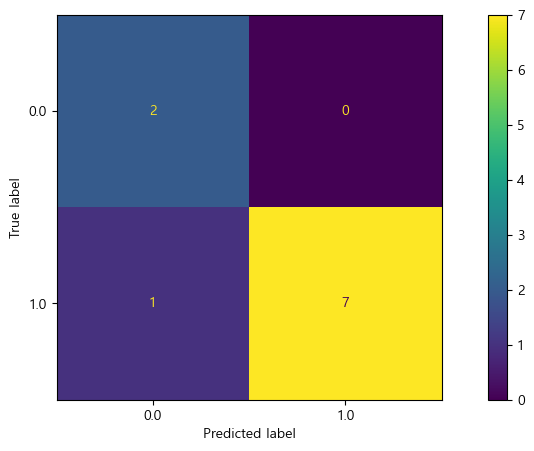

In [226]:
### 오차행렬표, 오차행렬도, 정확도, 정밀도, 재현율, f1-socre 확인하기
cn_matrix = confusion_matrix(test_target_10, test_temp, labels=rf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cn_matrix, display_labels=rf.classes_)
# 오차행렬표
confusion_matrix(test_target_10, test_temp, labels=rf.classes_)
# 오차행렬도
disp.plot()
plt.show()

In [227]:
# 정확도, 정밀도, 재현율, F1-Score 확인하기
# 정확도
test10_acc = accuracy_score(test_target_10, test_temp)
# 정밀도
test10_pre = precision_score(test_target_10, test_temp)
# 재현율
test10_rec = recall_score(test_target_10, test_temp)
# F1_Score 
test10_f1 = f1_score(test_target_10, test_temp)

print(f"정확도 : {test10_acc}, 정밀도 : {test10_pre}, 재현율 : {test10_rec}, F1-Score : {test10_f1}")

정확도 : 0.9, 정밀도 : 1.0, 재현율 : 0.875, F1-Score : 0.9333333333333333


### 훈련 및 테스트 데이터 전체로 성능평가하기

(5197,) (1300,)


array([[1272,    7],
       [   4, 3914]])

array([[237,  83],
       [ 61, 919]])

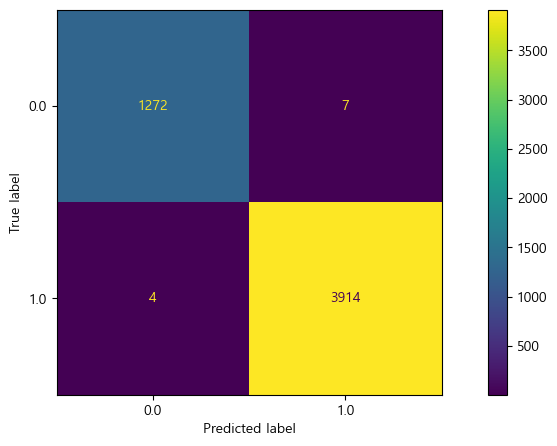

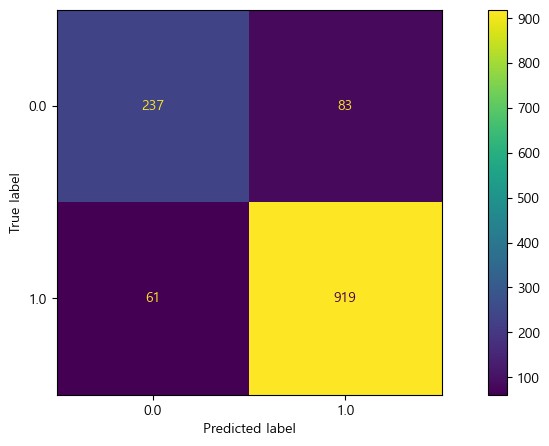

훈련정확도는0.99788339, 훈련정밀도는0.99821474, 훈련재현율은0.99897907, 훈련F1-Score는0.99859676
테스트정확도는0.88923077, 테스트정밀도는0.91716567, 테스트재현율은0.93775510, 테스트F1-Score는0.92734612
과적합여부 0.10865263


In [228]:
### 예측, 오차행렬표, 오차행렬도, 정확도, 정밀도, 재현율, f1-score 확인하기

# 예측하기
train_pred = rf.predict(train_scaled)
test_pred = rf.predict(test_scaled)
print(train_pred.shape, test_pred.shape)

# 오차행렬표
cn_train_matrix = confusion_matrix(train_target, train_pred, labels=rf.classes_)
display(cn_train_matrix)
cn_matrix = confusion_matrix(test_target, test_pred, labels=rf.classes_)
display(cn_matrix)

#오차행렬도
disp_train = ConfusionMatrixDisplay(confusion_matrix=cn_train_matrix, display_labels=rf.classes_)
disp_train
disp_train.plot()
plt.show()

disp = ConfusionMatrixDisplay(confusion_matrix=cn_matrix, display_labels=rf.classes_)
disp
disp.plot()
plt.show()

# 정확도
train_acc=accuracy_score(train_target, train_pred)
test_acc=accuracy_score(test_target, test_pred)
# 정밀도
train_pre=precision_score(train_target, train_pred)
test_pre=precision_score(test_target, test_pred)
# 재현율
train_rec=recall_score(train_target, train_pred)
test_rec=recall_score(test_target, test_pred)
# F1-Score
train_f1=f1_score(train_target, train_pred)
test_f1=f1_score(test_target, test_pred)
#
print(f"훈련정확도는{train_acc:.8f}, 훈련정밀도는{train_pre:.8f}, 훈련재현율은{train_rec:.8f}, 훈련F1-Score는{train_f1:.8f}")
print(f"테스트정확도는{test_acc:.8f}, 테스트정밀도는{test_pre:.8f}, 테스트재현율은{test_rec:.8f}, 테스트F1-Score는{test_f1:.8f}")
print(f"과적합여부{train_acc-test_acc: .8f}")

### 과대적합 발생 -> 하이퍼파라메터 튜닝 해보기 -> 다른 모델 사용해보기

In [289]:
### 랜덤포레스트 모델 사용....
# - 트리 갯수 조정하여 튜닝하기
# - 트리 갯수 하이퍼파라메터 변수명 : n_estimators : 기본값은 100
# - 데이터는 StandardScaler 데이터 사용
# - 트리의 갯수 10~100까지 적용하여 랜덤포레스트 과적합 확인해보기
# - CPU core는 전체 사용, 랜덤규칙 42 사용

hgb
hgb = HistGradientBoostingClassifier(random_state=42) #n_jobs=-1, 전체 사용한다는 말. 속도 향상
for n in range(10, 101, 1):
    hgb.max_iter=n
    #훈련해보기
    hgb.fit(train_scaled, train_target)
    #정확도확인
    train_score = hgb.score(train_scaled, train_target)
    test_score = hgb.score(test_scaled, test_target)
    #과적합 여부
    gap = train_score-test_score
        
    print(f"트리의 갯수[{n}], 훈련정확도{train_score:.5f}, 테스트정확도{test_score:.5f}, 과적합여부{gap:.5f}")


    

트리의 갯수[10], 훈련정확도0.88667, 테스트정확도0.85846, 과적합여부0.02820
트리의 갯수[11], 훈련정확도0.89032, 테스트정확도0.85615, 과적합여부0.03417
트리의 갯수[12], 훈련정확도0.89167, 테스트정확도0.85769, 과적합여부0.03398
트리의 갯수[13], 훈련정확도0.89321, 테스트정확도0.85846, 과적합여부0.03475
트리의 갯수[14], 훈련정확도0.89378, 테스트정확도0.86154, 과적합여부0.03225
트리의 갯수[15], 훈련정확도0.89513, 테스트정확도0.86077, 과적합여부0.03436
트리의 갯수[16], 훈련정확도0.89532, 테스트정확도0.86231, 과적합여부0.03302
트리의 갯수[17], 훈련정확도0.89552, 테스트정확도0.86231, 과적합여부0.03321
트리의 갯수[18], 훈련정확도0.89571, 테스트정확도0.86385, 과적합여부0.03186
트리의 갯수[19], 훈련정확도0.89667, 테스트정확도0.86462, 과적합여부0.03206
트리의 갯수[20], 훈련정확도0.89667, 테스트정확도0.86154, 과적합여부0.03513
트리의 갯수[21], 훈련정확도0.89667, 테스트정확도0.86000, 과적합여부0.03667
트리의 갯수[22], 훈련정확도0.89667, 테스트정확도0.86000, 과적합여부0.03667
트리의 갯수[23], 훈련정확도0.89648, 테스트정확도0.86154, 과적합여부0.03494
트리의 갯수[24], 훈련정확도0.89763, 테스트정확도0.86077, 과적합여부0.03686
트리의 갯수[25], 훈련정확도0.89898, 테스트정확도0.86231, 과적합여부0.03667
트리의 갯수[26], 훈련정확도0.90187, 테스트정확도0.86692, 과적합여부0.03494
트리의 갯수[27], 훈련정확도0.90187, 테스트정확도0.86615, 과적합여부0.03571
트리의 갯수[28], 훈련정확도0.90264, 테스

## 5개 앙상블 모델을 모두 사용하여 과적합 여부까지만 확인해보기

In [230]:
### 10~100까지만 반복...
# - 일반화 가능한 모델이 있는지 확인해 주세요..
model_list = [RandomForestClassifier(random_state=42, n_jobs=-1),
              ExtraTreesClassifier(random_state=42, n_jobs=-1),
              GradientBoostingClassifier(random_state=42),
              HistGradientBoostingClassifier(random_state=42),
              XGBClassifier(random_state=42, n_jobs=-1)]

result = []

for m in model_list :
    model_name = m.__class__.__name__
    print("===================================================================================")
    for n in range(10, 101, 1):
        m.n_estimators=n
        #훈련해보기
        m.fit(train_scaled, train_target)
        #정확도확인
        train_score = m.score(train_scaled, train_target)
        test_score = m.score(test_scaled, test_target)
        #과적합 여부
        gap = train_score-test_score
            
        print(f"모델명[{model_name}], 트리의 갯수[{n}], \n훈련정확도{train_score:.5f}, 테스트정확도{test_score:.5f}, 과적합여부{gap:.5f}")

        if (train_score < 1) and ( train_score > 0.9) and (test_score > 0.86) and (gap < 0.10):
            result.append((f"모델명[{model_name}], 트리의 갯수[{n}], \n훈련정확도{train_score:.5f}, 테스트정확도{test_score:.5f}, 과적합여부{gap:.5f}"))


모델명[RandomForestClassifier], 트리의 갯수[10], 
훈련정확도0.99096, 테스트정확도0.88615, 과적합여부0.10480
모델명[RandomForestClassifier], 트리의 갯수[11], 
훈련정확도0.99057, 테스트정확도0.88923, 과적합여부0.10134
모델명[RandomForestClassifier], 트리의 갯수[12], 
훈련정확도0.99327, 테스트정확도0.88538, 과적합여부0.10788
모델명[RandomForestClassifier], 트리의 갯수[13], 
훈련정확도0.99327, 테스트정확도0.88692, 과적합여부0.10634
모델명[RandomForestClassifier], 트리의 갯수[14], 
훈련정확도0.99288, 테스트정확도0.88154, 과적합여부0.11134
모델명[RandomForestClassifier], 트리의 갯수[15], 
훈련정확도0.99250, 테스트정확도0.88692, 과적합여부0.10557
모델명[RandomForestClassifier], 트리의 갯수[16], 
훈련정확도0.99384, 테스트정확도0.88615, 과적합여부0.10769
모델명[RandomForestClassifier], 트리의 갯수[17], 
훈련정확도0.99346, 테스트정확도0.88846, 과적합여부0.10500
모델명[RandomForestClassifier], 트리의 갯수[18], 
훈련정확도0.99423, 테스트정확도0.88385, 과적합여부0.11038
모델명[RandomForestClassifier], 트리의 갯수[19], 
훈련정확도0.99365, 테스트정확도0.88308, 과적합여부0.11057
모델명[RandomForestClassifier], 트리의 갯수[20], 
훈련정확도0.99423, 테스트정확도0.88385, 과적합여부0.11038
모델명[RandomForestClassifier], 트리의 갯수[21], 
훈련정확도0.99500, 테스트정확도0.88154, 과적합여부

KeyboardInterrupt: 

In [ ]:
display(result)

['모델명[HistGradientBoostingClassifier], 트리의 갯수[10], \n훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900',
 '모델명[HistGradientBoostingClassifier], 트리의 갯수[11], \n훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900',
 '모델명[HistGradientBoostingClassifier], 트리의 갯수[12], \n훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900',
 '모델명[HistGradientBoostingClassifier], 트리의 갯수[13], \n훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900',
 '모델명[HistGradientBoostingClassifier], 트리의 갯수[14], \n훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900',
 '모델명[HistGradientBoostingClassifier], 트리의 갯수[15], \n훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900',
 '모델명[HistGradientBoostingClassifier], 트리의 갯수[16], \n훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900',
 '모델명[HistGradientBoostingClassifier], 트리의 갯수[17], \n훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900',
 '모델명[HistGradientBoostingClassifier], 트리의 갯수[18], \n훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900',
 '모델명[HistGradientBoostingClassifier], 트리의 갯수[19], \n훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900',
 '모델명[HistGradientBoostingClas

In [295]:
### 트리갯수 10~100까지 사용(반복)..
# - 일반화 가능한 모델이 있는지 확인해 주세요..
gb  = GradientBoostingClassifier(random_state=42)
rgb = HistGradientBoostingClassifier(random_state=42)
xgb = XGBClassifier(random_state=42, n_jobs=-1)


model_list = [gb, rgb, xgb]


for model in model_list :
    model_name = model.__class__.__name__
    print(f"=========== [{model_name}] ============")

    for n in range(10, 101, 1) :    
        if m.n_estimators:
            m.n_estimators = n
        else:
            m.max_iter = n
        model.fit(train_scaled, train_target)


        train_score = model.score(train_scaled, train_target)
        test_score = model.score(test_scaled, test_target)
        train_test = train_score - test_score

        print(f"모델명[{model_name}], 트리의 갯수[{n}], \n훈련정확도{train_score:.5f}, 테스트정확도{test_score:.5f}, 과적합여부{train_test:.5f}")


print("작업 종료..........")            


### GB[10] : 훈련정확도0.85049, 테스트정확도0.83846, 과적합여부0.01203
### HGB[10] : 훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900
### XGBClassifier[14] : 훈련정확도0.89282, 테스트정확도0.86846, 과적합여부0.02436



=========== [GradientBoostingClassifier] ============
모델명[GradientBoostingClassifier], 트리의 갯수[10], 
훈련정확도0.88339, 테스트정확도0.85769, 과적합여부0.02570
모델명[GradientBoostingClassifier], 트리의 갯수[11], 
훈련정확도0.88339, 테스트정확도0.85769, 과적합여부0.02570
모델명[GradientBoostingClassifier], 트리의 갯수[12], 
훈련정확도0.88339, 테스트정확도0.85769, 과적합여부0.02570
모델명[GradientBoostingClassifier], 트리의 갯수[13], 
훈련정확도0.88339, 테스트정확도0.85769, 과적합여부0.02570
모델명[GradientBoostingClassifier], 트리의 갯수[14], 
훈련정확도0.88339, 테스트정확도0.85769, 과적합여부0.02570
모델명[GradientBoostingClassifier], 트리의 갯수[15], 
훈련정확도0.88339, 테스트정확도0.85769, 과적합여부0.02570
모델명[GradientBoostingClassifier], 트리의 갯수[16], 
훈련정확도0.88339, 테스트정확도0.85769, 과적합여부0.02570
모델명[GradientBoostingClassifier], 트리의 갯수[17], 
훈련정확도0.88339, 테스트정확도0.85769, 과적합여부0.02570
모델명[GradientBoostingClassifier], 트리의 갯수[18], 
훈련정확도0.88339, 테스트정확도0.85769, 과적합여부0.02570
모델명[GradientBoostingClassifier], 트리의 갯수[19], 
훈련정확도0.88339, 테스트정확도0.85769, 과적합여부0.02570
모델명[GradientBoostingClassifier], 트리의 갯수[20], 
훈련정확도0.88339, 테스트정확도

### 일반화가 잘된 모델들에 대해서 예측 및 평가하여 최종 모델 선정하기

In [ ]:
### GB[10] : 훈련정확도0.85049, 테스트정확도0.83846, 과적합여부0.01203
### HGB[10] : 훈련정확도0.92669, 테스트정확도0.87769, 과적합여부0.04900
### XGBClassifier[14] : 훈련정확도0.89282, 테스트정확도0.86846, 과적합여부0.02436

### 훈련 데이터만 사용해서 진행
# 예측하기
gb  = GradientBoostingClassifier(random_state=42, n_estimators=10)
# hgb = HistGradientBoostingClassifier(random_state=42, n_estimators=10)
hgb = HistGradientBoostingClassifier(random_state=42, max_iter=100)
xgb = XGBClassifier(random_state=42, n_jobs=-1, n_estimators=14)


model_list = [gb, hgb, xgb]

for m in model_list:
    # 모델이름 
    model_name = m.__class__.__name__
    # 패턴 찾기
    m.fit(train_scaled, train_target)
    # 예측
    train_pred = m.predict(train_scaled)
    
    # 정확도
    train_acc=accuracy_score(train_target, train_pred)
    # 정밀도
    train_pre=precision_score(train_target, train_pred)
    # 재현율
    train_rec=recall_score(train_target, train_pred)
    # F1-Score
    train_f1=f1_score(train_target, train_pred)

    print(f"[{model_name}],정확도[{train_acc}], 정밀도[{train_pre}], 재현율[{train_rec}], F1-Score[{train_f1}]")

    # 해석
    # hgb 선정

[GradientBoostingClassifier],정확도[0.8504906676928997], 정밀도[0.8545947166403252], 재현율[0.9660541092394078], F1-Score[0.906912663232299]
[HistGradientBoostingClassifier],정확도[0.9266884741196845], 정밀도[0.9508029569207239], 재현율[0.9520163348647269], F1-Score[0.9514092590230838]
[XGBClassifier],정확도[0.8928227823744468], 정밀도[0.9261983261476033], 재현율[0.9321082184788158], F1-Score[0.9291438748250859]


,loss,'log_loss'
,learning_rate,0.1
,max_iter,100
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None
